In [2]:
import os
import time
import pandas as pd
import numpy as np

# 1. Definir rutas
path_csv = "../data/raw/operaciones-aeropuertos.csv"
path_parquet = "../data/raw/bitacora-vuelos.parquet"

# 2. Evaluación del archivo Parquet 
start_time = time.time()
df = pd.read_parquet(path_parquet)
time_parquet = time.time() - start_time

mem_parquet = df.memory_usage(deep=True).sum() / (1024**2) # MB
size_parquet = os.path.getsize(path_parquet) / (1024**2)  # MB

print("--- PERFILAMIENTO TÉCNICO PARQUET ---")
print(f"Dimensiones (Shape) : {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Tamaño en disco    : {size_parquet:.2f} MB")
print(f"Tiempo de carga    : {time_parquet:.4f} segundos")
print(f"Uso de memoria RAM : {mem_parquet:.2f} MB")
print("\n--- PRIMEROS REGISTROS ---")
df.head(3)

--- PERFILAMIENTO TÉCNICO PARQUET ---
Dimensiones (Shape) : 11,163,791 filas x 12 columnas
Tamaño en disco    : 131.84 MB
Tiempo de carga    : 6.9549 segundos
Uso de memoria RAM : 2529.24 MB

--- PRIMEROS REGISTROS ---


,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
0,1999-12-31 21:00:00-03:00,SCEL,A,SPIM,LAN,631,U,CCCDM,B763,767-352ER,True,187.00000
1,1999-12-31 21:00:00-03:00,SCTC,D,SCUG,6,0,P,CCSPC,C172,172B,False,1.00000
2,1999-12-31 21:04:00.001000-03:00,SCEL,A,SCTC,LAN,4248,U,CCCHS,EC35,EC-135 T2,False,2.84000


In [3]:
# Inspección de tipos e integridad
print("--- TIPOS DE DATOS Y VALORES AUSENTES ---")
perfilamiento = pd.DataFrame({
    'Tipo_Dato': df.dtypes,
    'Valores_Nulos': df.isna().sum(),
    'Porcentaje_Nulos (%)': (df.isna().sum() / len(df) * 100).round(2),
    'Valores_Unicos': df.nunique()
})
perfilamiento

--- TIPOS DE DATOS Y VALORES AUSENTES ---


,Tipo_Dato,Valores_Nulos,Porcentaje_Nulos (%),Valores_Unicos
dt_operacion,"datetime64[us, America/Santiago]",0,0.00,6527475
aeropuerto_oaci,str,0,0.00,69
tipo_operacion,str,0,0.00,4
aeropuerto_dgac_orig_dest,str,0,0.00,1671
aerolinea_dgac,str,0,0.00,2568
numero_vuelo,str,482145,4.32,7442
actividad_cod,str,0,0.00,26
matricula,str,0,0.00,13835
modelo_avion,str,0,0.00,1286
modelo_avion_desc,str,0,0.00,2325


In [4]:
# --- PREPARACIÓN E INGENIERÍA DE VARIABLES ---

df_proc = df.copy()

# 1. Normalización de cadenas y tipos
df_proc['aerolinea_dgac'] = df_proc['aerolinea_dgac'].astype(str).str.strip().str.upper()
df_proc['aeropuerto_oaci'] = df_proc['aeropuerto_oaci'].astype(str).str.strip().str.upper()

# 2. Conversión de PMD a numérico (trata errores/caracteres como NaN)
if 'pmd' in df_proc.columns:
    df_proc['pmd'] = pd.to_numeric(df_proc['pmd'], errors='coerce')

# 3. Tratamiento justificado de nulos en número de vuelo
# Los vuelos sin número corresponden principalmente a aviación general/privada (no comercial)
df_proc['numero_vuelo'] = df_proc['numero_vuelo'].fillna('SIN_NUMERO')

# 4. INGENIERÍA DE VARIABLES (3 Variables Derivadas)
# V1: Año de la operación
df_proc['anio'] = df_proc['dt_operacion'].dt.year

# V2: Mes de la operación (1-12)
df_proc['mes'] = df_proc['dt_operacion'].dt.month

# V3: Trimestre / Quarter (Q1-Q4)
df_proc['trimestre'] = df_proc['dt_operacion'].dt.quarter

# 5. Guardar el dataset procesado 
output_path = "../data/processed/transportes_procesado.parquet"
df_proc.to_parquet(output_path, index=False)

print("--- PROCESAMIENTO FINALIZADO ---")
print(f"Dataset procesado guardado en: {output_path}")
print(f"Dimensiones finales: {df_proc.shape[0]:,} filas x {df_proc.shape[1]} columnas")
df_proc[['dt_operacion', 'anio', 'mes', 'trimestre', 'aerolinea_dgac', 'es_internacional']].head(3)

--- PROCESAMIENTO FINALIZADO ---
Dataset procesado guardado en: ../data/processed/transportes_procesado.parquet
Dimensiones finales: 11,163,791 filas x 15 columnas


,dt_operacion,anio,mes,trimestre,aerolinea_dgac,es_internacional
0,1999-12-31 21:00:00-03:00,1999,12,4,LAN,True
1,1999-12-31 21:00:00-03:00,1999,12,4,6,False
2,1999-12-31 21:04:00.001000-03:00,1999,12,4,LAN,False


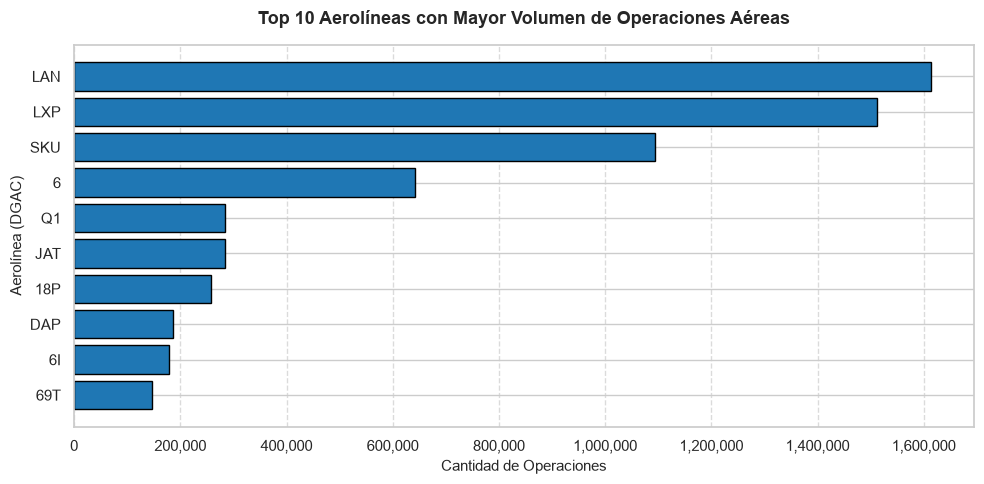

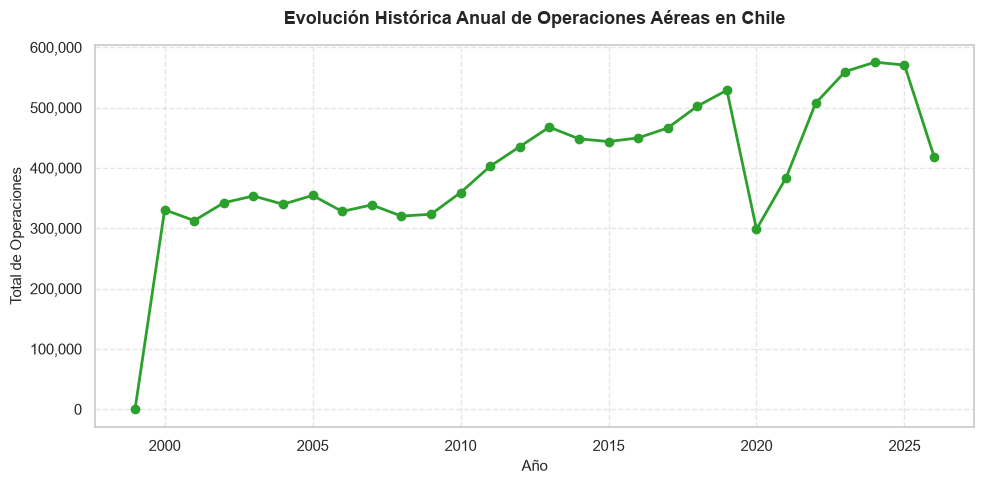

C:\Users\BRYAN-CARRASCO\AppData\Local\Temp\ipykernel_12100\4128963061.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_proc, x='mes', palette='viridis')


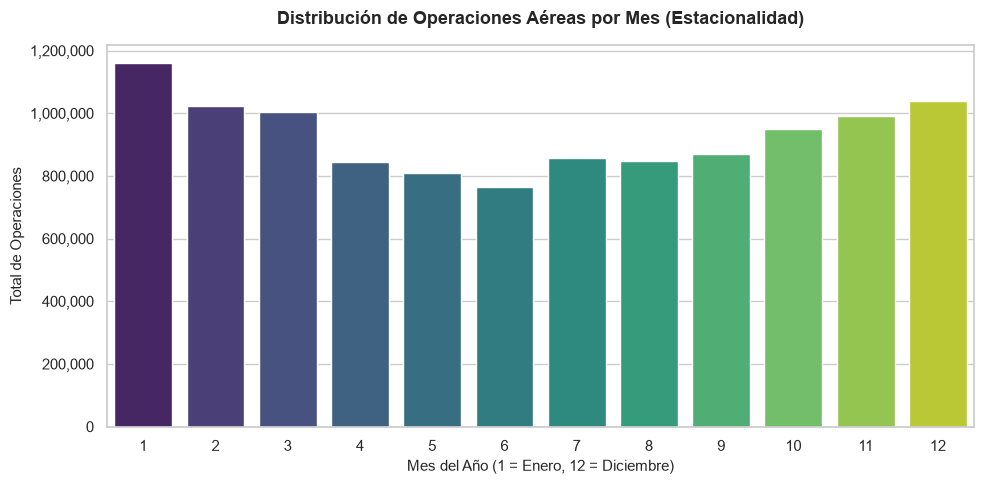

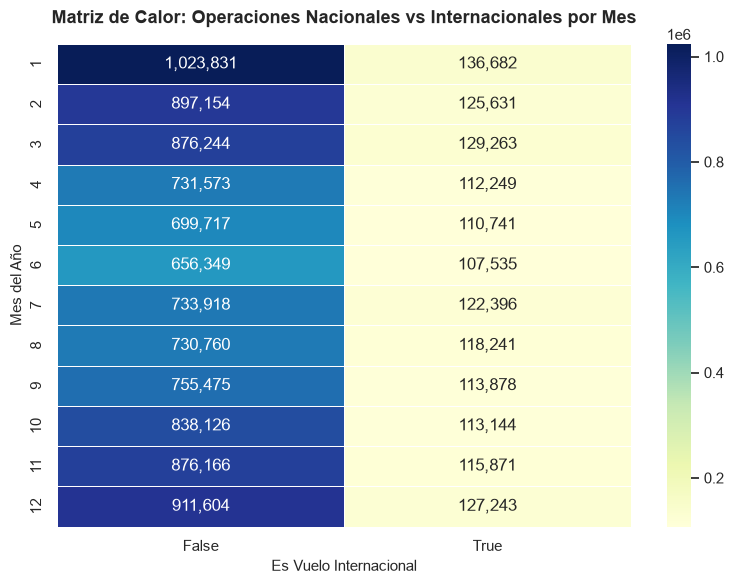

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df_proc = pd.read_parquet("../data/processed/transportes_procesado.parquet")

# Configuración de estilo global
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# ---------------------------------------------------------
# GRAFICO 1: Matplotlib - Top 10 Aerolíneas (Comparación)
# ---------------------------------------------------------
top_aerolineas = df_proc['aerolinea_dgac'].value_counts().head(10)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_aerolineas.index[::-1], top_aerolineas.values[::-1], color='#1f77b4', edgecolor='black')
ax.set_title("Top 10 Aerolíneas con Mayor Volumen de Operaciones Aéreas", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Cantidad de Operaciones", fontsize=11)
ax.set_ylabel("Aerolínea (DGAC)", fontsize=11)
ax.xaxis.set_major_formatter('{x:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig("../output/figures/01_matplotlib_top_aerolineas.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# GRAFICO 2: Matplotlib - Evolución Anual de Operaciones
# ---------------------------------------------------------
evolucion_anual = df_proc.groupby('anio').size()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(evolucion_anual.index, evolucion_anual.values, marker='o', color='#2ca02c', linewidth=2, markersize=6)
ax.set_title("Evolución Histórica Anual de Operaciones Aéreas en Chile", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Año", fontsize=11)
ax.set_ylabel("Total de Operaciones", fontsize=11)
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("../output/figures/02_matplotlib_evolucion_anual.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# GRAFICO 3: Seaborn - Distribución Mensual (Estacionalidad)
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df_proc, x='mes', palette='viridis')
plt.title("Distribución de Operaciones Aéreas por Mes (Estacionalidad)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Mes del Año (1 = Enero, 12 = Diciembre)", fontsize=11)
plt.ylabel("Total de Operaciones", fontsize=11)
ax.yaxis.set_major_formatter('{x:,.0f}')

plt.tight_layout()
plt.savefig("../output/figures/03_seaborn_distribucion_mes.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# GRAFICO 4: Seaborn - Matriz de Calor (Mes vs Vuelos Internacionales)
# ---------------------------------------------------------
pivot_operaciones = df_proc.pivot_table(index='mes', columns='es_internacional', values='dt_operacion', aggfunc='count')

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_operaciones, cmap='YlGnBu', annot=True, fmt=',d', linewidths=.5)
plt.title("Matriz de Calor: Operaciones Nacionales vs Internacionales por Mes", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Es Vuelo Internacional", fontsize=11)
plt.ylabel("Mes del Año", fontsize=11)

plt.tight_layout()
plt.savefig("../output/figures/04_seaborn_heatmap_vuelos.png", dpi=300)
plt.show()

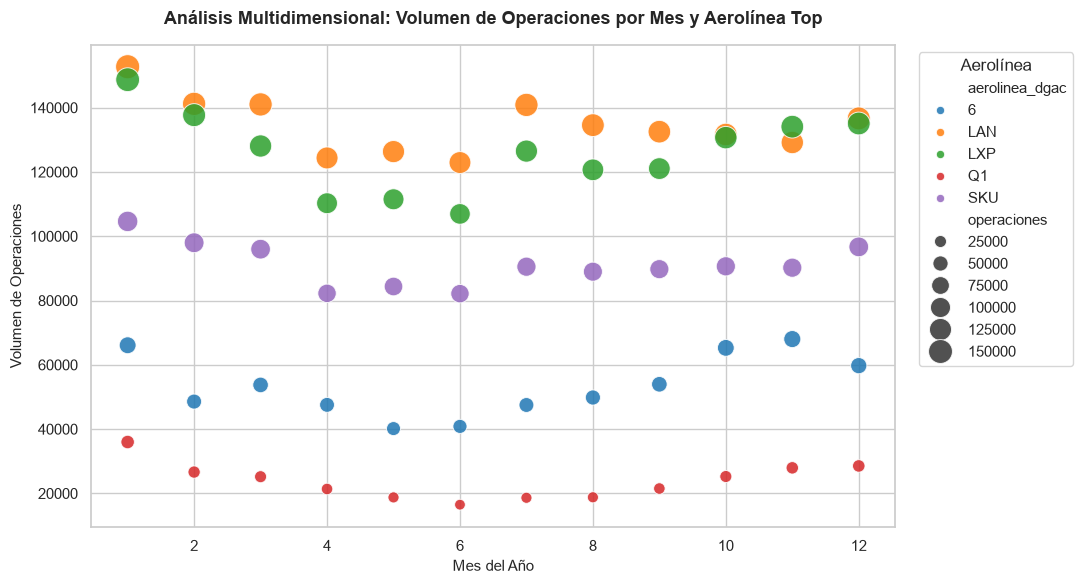

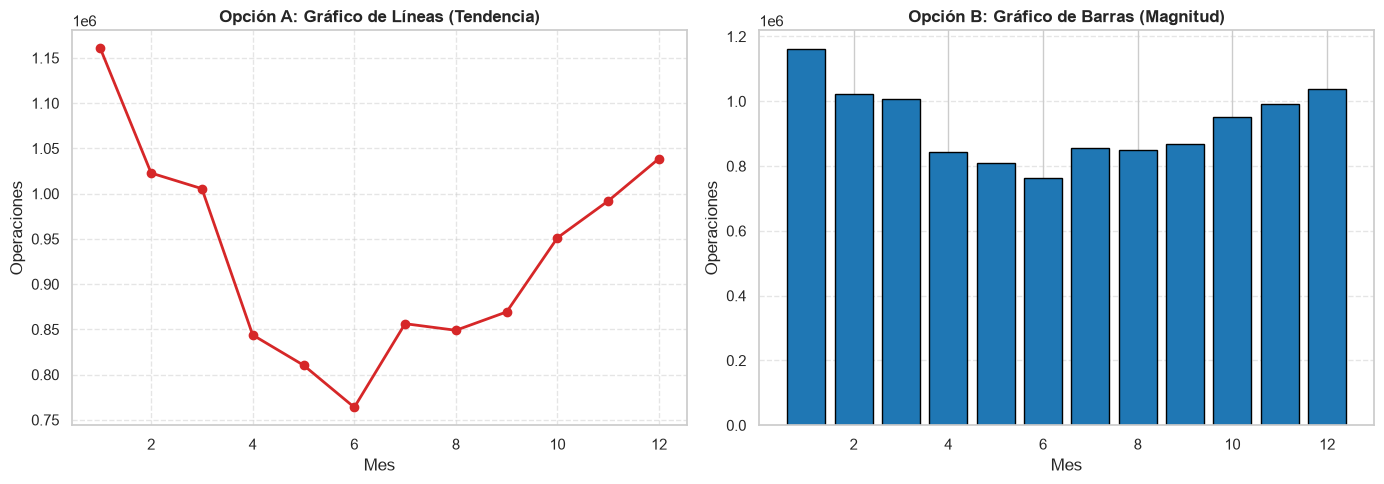

In [4]:
# ---------------------------------------------------------
# GRAFICO 5: Visualización Multidimensional 
# Variables: X=Mes, Y=Operaciones, Hue=Aerolínea Top, Size=Operaciones
# ---------------------------------------------------------
# Agrupación multidimensional
top_lines = df_proc['aerolinea_dgac'].value_counts().head(5).index
df_multi = df_proc[df_proc['aerolinea_dgac'].isin(top_lines)].groupby(['mes', 'aerolinea_dgac']).size().reset_index(name='operaciones')

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_multi,
    x='mes',
    y='operaciones',
    hue='aerolinea_dgac',
    size='operaciones',
    sizes=(60, 300),
    palette='tab10',
    alpha=0.85
)

plt.title("Análisis Multidimensional: Volumen de Operaciones por Mes y Aerolínea Top", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Mes del Año", fontsize=11)
plt.ylabel("Volumen de Operaciones", fontsize=11)
plt.legend(title="Aerolínea", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig("../output/figures/05_multidimensional_aerolineas.png", dpi=300)
plt.show()

# ---------------------------------------------------------
# BENCHMARK VISUAL: Comparación de la misma pregunta
# Pregunta: ¿Cómo evoluciona la distribución mensual del tráfico?
# opción A: Gráfico de Líneas vs Opción B: Gráfico de Barras
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

mes_ops = df_proc.groupby('mes').size()

# Opción A: Línea
ax1.plot(mes_ops.index, mes_ops.values, marker='o', color='#d62728', linewidth=2)
ax1.set_title("Opción A: Gráfico de Líneas (Tendencia)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Mes")
ax1.set_ylabel("Operaciones")
ax1.grid(True, linestyle='--', alpha=0.5)

# Opción B: Barras
ax2.bar(mes_ops.index, mes_ops.values, color='#1f77b4', edgecolor='black')
ax2.set_title("Opción B: Gráfico de Barras (Magnitud)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Mes")
ax2.set_ylabel("Operaciones")
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("../output/figures/06_benchmark_visual_comparacion.png", dpi=300)
plt.show()